# Assignment 2：資料初探

使用官方 `preprocess.py` 產生的 8 張匿名化表格。此 Notebook 已執行並保留輸出；
之後更新資料，可以重新 **Run All**。在 VS Code 請選 conda **bigdata** 的 Python；
也可以在作業根目錄執行 `conda activate bigdata` 後開啟 `jupyter lab`。

閱讀順序：資料範圍 → 表格與欄位 → 關聯與覆蓋率 → 活動推估 → 時間與使用者分布 → 後續分析。
輸出 CSV、圖檔和摘要會寫入 `data/analysis/`。本 Notebook 不會下載資料、修改原始表格或提交預測。

依據：[作業 README](../README.md)、[欄位說明 SCHEMA](../SCHEMA.md)、[環境與資料建置](../SETUP.md)。
所有日期分組使用 **UTC**，區間採 **左含右不含**。測試週起點為台灣時間 2026/11/22 00:00，
即 UTC 2026/11/21 16:00。名稱雜湊、文字 `aaaa`／`0000` 都是預期的匿名化結果。

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display

# 支援從專案根目錄或 notebooks/ 啟動。
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'scripts/preprocess.py').is_file()
             and (p / 'submission/test_input.csv').is_file()), None)
if ROOT is None:
    raise RuntimeError('請從 Assignment2 專案或其 notebooks/ 子目錄啟動。')
sys.path.insert(0, str(ROOT / 'scripts'))
from preprocess import TABLES, load_cohort
from check_setup import check_tables

DB = ROOT / 'data/processed/db'
OUT = ROOT / 'data/analysis'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.2})

def save_figure(fig, filename):
    fig.savefig(OUT / filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python:', sys.executable)
print('Project:', ROOT)
print({p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'pyarrow', 'matplotlib']})

Python: /home/asiadragon/miniconda3/envs/bigdata/bin/python
Project: /home/asiadragon/geolife/bigdata_asg/BigData2026-Assignment2
{'pandas': '3.0.6', 'numpy': '2.4.6', 'pyarrow': '26.0.0', 'matplotlib': '3.11.2'}


## 1. 確認資料範圍與來源

讀取建置紀錄，並驗證每一個預期的小時檔都存在。**下載檔案完整**只代表取得了該小時的來源檔，
不代表 GH Archive 收錄了所有 GitHub 活動。缺檔、來源內容不完整和使用者沒有活動是不同問題。
若 manifest 與表格檢查結果不一致，先完成資料建置，再做分析。

In [2]:
manifest = json.loads((ROOT / 'data/download_manifest.json').read_text())
build = json.loads((ROOT / 'data/build_summary.json').read_text())
DATA_START = pd.Timestamp(manifest['start_utc_inclusive']).tz_localize(None)
DATA_END = pd.Timestamp(manifest['end_utc_exclusive']).tz_localize(None)
TEST_START = pd.Timestamp('2026-11-21 16:00:00')
expected_hours = pd.date_range(DATA_START, DATA_END, freq='h', inclusive='left')
files = pd.DataFrame(manifest['files'])
files['hour_utc'] = pd.to_datetime(files['hour_utc'], utc=True).dt.tz_localize(None)
assert len(files) == files['hour_utc'].nunique() == len(expected_hours)
assert set(files['hour_utc']) == set(expected_hours)
assert files['status'].isin(['existing', 'downloaded']).all()
raw = ROOT / 'data/raw/gharchive'
assert set(files['file']) == {p.name for p in raw.glob('*.json.gz')}
assert all((raw / r.file).stat().st_size == r.bytes for r in files.itertuples())
assert build['period_utc_exclusive'] == manifest['end_utc_exclusive']
assert build['period_utc_inclusive'] == manifest['start_utc_inclusive']
assert DATA_END <= TEST_START, '本次分析資料已進入測試週，需重新設定可用範圍。'

source = json.loads((ROOT / 'data/environment_snapshot.json').read_text())
for filename, digest in source.get('official_files_sha256', {}).items():
    assert hashlib.sha256((ROOT / filename).read_bytes()).hexdigest() == digest, filename

daily_files = files.groupby(files['hour_utc'].dt.floor('D')).agg(
    available_hours=('file', 'count'), raw_bytes=('bytes', 'sum'))
display(pd.DataFrame([{
    'start_utc_inclusive': DATA_START, 'end_utc_exclusive': DATA_END,
    'complete_utc_days': len(daily_files), 'hour_files': len(files),
    'raw_GiB': round(files['bytes'].sum() / 1024**3, 3),
    'min_hours_per_day': daily_files['available_hours'].min(),
    'test_start_utc': TEST_START,
}]))
display(daily_files.tail(8))

,start_utc_inclusive,end_utc_exclusive,complete_utc_days,hour_files,raw_GiB,min_hours_per_day,test_start_utc
0,2026-10-01,2026-11-18,48,1152,9.147,24,2026-11-21 16:00:00


,available_hours,raw_bytes
hour_utc,,
2026-11-10,24,81436858
2026-11-11,24,99234408
2026-11-12,24,93491458
2026-11-13,24,113314537
2026-11-14,24,139969430
2026-11-15,24,150232227
2026-11-16,24,125709830
2026-11-17,24,87669374


## 2. 8 張表概況與內容預覽

每張表的主鍵是當次建表的列號；擴大資料範圍後，列號可能改變。
與正式測試清單對接時，使用 **`UserID = Users.github_user_id`**。
同一張表的一列代表一個物件，例如一個 PR；PR 的開啟、關閉、合併不會各存成一列。

/tmp/ipykernel_2313448/2336687631.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(overview.round(3))


,rows,columns,row_time,first_row_utc,last_row_utc,parquet_MiB
table,,,,,,
Users,5964,6,first_seen_at,2026-10-01 00:00:23,2026-11-17 19:26:41,0.246
Repositories,12733,7,first_seen_at,2026-10-01 00:00:23,2026-11-17 23:44:00,0.733
PullRequests,14554,18,first_seen_at,2026-10-01 00:00:23,2026-11-17 23:50:47,1.323
Issues,9279,20,first_seen_at,2026-10-01 00:00:27,2026-11-17 22:50:49,8.217
IssueComments,3673,10,created_at,2026-10-01 00:00:27,2026-11-17 22:50:49,1.251
PRReviews,3563,12,first_seen_at,2026-10-01 00:12:37,2026-11-17 23:46:34,0.668
PRReviewComments,1797,17,created_at,2026-10-01 00:00:23,2026-11-17 09:18:58,2.656
Pushes,43545,10,created_at,2026-10-01 00:00:29,2026-11-17 15:08:11,2.365


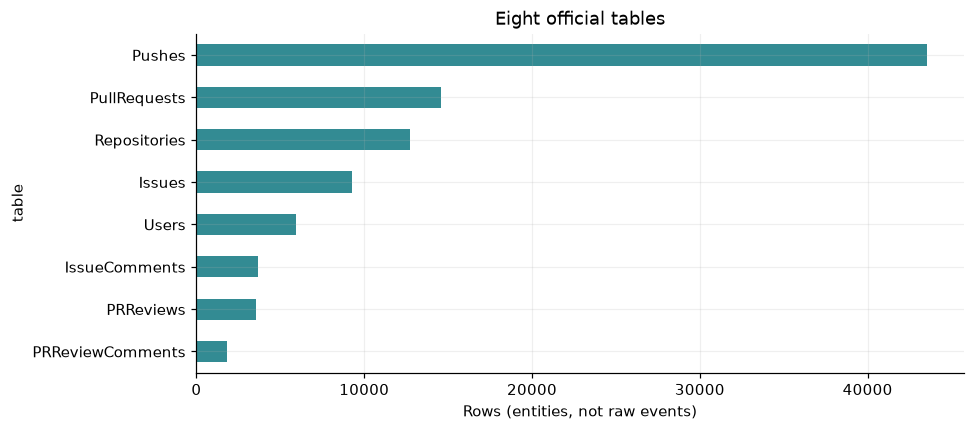

In [3]:
tables = {name: pd.read_parquet(DB / f'{name}.parquet') for name in TABLES}
overview = pd.DataFrame([
    {'table': name, 'rows': len(df), 'columns': len(df.columns),
     'row_time': TABLES[name]['time'],
     'first_row_utc': df[TABLES[name]['time']].min(),
     'last_row_utc': df[TABLES[name]['time']].max(),
     'parquet_MiB': (DB / f'{name}.parquet').stat().st_size / 1024**2}
    for name, df in tables.items()
]).set_index('table')
for name, df in tables.items():
    assert len(df) == build['tables'][name], f'{name}: 建置摘要過期'
    assert df[TABLES[name]['time']].ge(DATA_START).all()
    assert df[TABLES[name]['time']].lt(DATA_END).all()
display(overview.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
overview['rows'].sort_values().plot.barh(ax=ax, color='#338b93')
ax.set(xlabel='Rows (entities, not raw events)', title='Eight official tables')
save_figure(fig, 'table_sizes.png')

In [17]:
# 修改這三個參數後重跑本格，可以查看任一張表。
TABLE_NAME = 'Pushes'
N_ROWS = 8
COLUMNS = None  # 例如 ['pr_id', 'repo_id', 'author_id', 'created_at', 'first_seen_at']



for table in tables:
    print(table)
    view = tables[table]
    display(pd.DataFrame({'column': view.columns,
                        'dtype': [str(t) for t in view.dtypes],
                        'null_count': view.isna().sum().to_numpy()}))

Users


,column,dtype,null_count
0,user_id,int64,0
1,github_user_id,Int64,0
2,login,str,0
3,is_bot,boolean,0
4,is_cohort,boolean,0
5,first_seen_at,datetime64[ns],0


Repositories


,column,dtype,null_count
0,repo_id,int64,0
1,github_repo_id,Int64,0
2,name,str,0
3,owner_login,str,0
4,org_id,Int64,7193
5,org_login,str,7193
6,first_seen_at,datetime64[ns],0


PullRequests


,column,dtype,null_count
0,pr_id,int64,0
1,github_pr_id,Int64,0
2,repo_id,Int64,0
3,number,Int64,0
4,author_id,Int64,9858
5,title,str,14379
6,draft,boolean,14379
7,head_ref,str,0
8,base_ref,str,0
9,head_sha,str,0


... (6 outputs left out)

PRReviewComments


,column,dtype,null_count
0,comment_id,int64,0
1,github_comment_id,Int64,0
2,pr_id,Int64,0
3,repo_id,Int64,0
4,author_id,Int64,0
5,pull_request_review_id,Int64,1599
6,in_reply_to_id,Int64,1795
7,path,str,0
8,file_extension,str,12
9,subject_type,str,0


Pushes


,column,dtype,null_count
0,push_id,int64,0
1,github_push_id,Int64,0
2,user_id,Int64,0
3,repo_id,Int64,0
4,ref,str,0
5,ref_type,str,0
6,branch,str,0
7,is_new_ref,boolean,0
8,created_at,datetime64[ns],0
9,event_id,str,0


## 3. 缺值、主鍵與外鍵品質

缺值不一定是錯誤：例如官方文件說明 PR 作者可能未知，review 的 parent 物件可能不在資料中，
並會以 null 外鍵表示。先記錄缺值分布，再決定特徵補值策略。
外鍵是列號；`head_repo_id` 等標為 code 的欄位不應誤當作外鍵。

In [5]:
verification = check_tables(DB)
column_profile = pd.DataFrame([
    {'table': name, 'column': col, 'dtype': str(df[col].dtype),
     'rows': len(df), 'null_count': int(df[col].isna().sum()),
     'null_rate': float(df[col].isna().mean()) if len(df) else np.nan,
     'unique_non_null': int(df[col].nunique(dropna=True))}
    for name, df in tables.items() for col in df.columns
])
fk_profile = []
for name, spec in TABLES.items():
    for column, target in spec['fks'].items():
        values = tables[name][column]
        valid_keys = tables[target][TABLES[target]['pk']]
        fk_profile.append({'table': name, 'foreign_key': column, 'target': target,
                           'null_rate': values.isna().mean(),
                           'invalid_non_null': int((values.notna() & ~values.isin(valid_keys)).sum())})
fk_profile = pd.DataFrame(fk_profile)
assert fk_profile['invalid_non_null'].sum() == 0
display(column_profile.loc[column_profile['null_count'].gt(0)]
        .sort_values(['null_rate', 'table'], ascending=[False, True]).head(25))
display(fk_profile)
print('PASS: 8 張表的型別、主鍵、外鍵、時間排序與 cohort 標記均通過檢查。')

,table,column,dtype,rows,null_count,null_rate,unique_non_null
79,PRReviewComments,in_reply_to_id,Int64,1797,1795,0.998887,2
18,PullRequests,title,str,14554,14379,0.987976,175
19,PullRequests,draft,boolean,14554,14379,0.987976,2
37,Issues,pull_request_id,Int64,9279,9104,0.981140,175
70,PRReviews,dismissed_at,datetime64[ns],3563,3488,0.978950,72
44,Issues,issue_type,str,9279,8681,0.935553,8
46,Issues,created_via_app,str,9279,8365,0.901498,15
78,PRReviewComments,pull_request_review_id,Int64,1797,1599,0.889816,198
43,Issues,milestone_title,str,9279,8145,0.877789,231
58,IssueComments,via_app,str,3673,3197,0.870406,12


,table,foreign_key,target,null_rate,invalid_non_null
0,PullRequests,repo_id,Repositories,0.000000,0
1,PullRequests,author_id,Users,0.677340,0
2,PullRequests,merged_by_id,Users,0.719184,0
3,Issues,repo_id,Repositories,0.000000,0
4,Issues,author_id,Users,0.000000,0
5,Issues,pull_request_id,PullRequests,0.981140,0
6,Issues,assignee_id,Users,0.815713,0
7,IssueComments,issue_id,Issues,0.000000,0
8,IssueComments,repo_id,Repositories,0.000000,0
9,IssueComments,author_id,Users,0.000000,0


PASS: 8 張表的型別、主鍵、外鍵、時間排序與 cohort 標記均通過檢查。


## 4. 測試使用者與 cohort 覆蓋率

只有 cohort 使用者自己的活動會完整進入官方篩選流程；其他使用者只是關聯物件，活動不完整。
**有 Users 列**和**有可歸屬的活動記錄**也不同；下方先檢查前者，稍後再計算後者。
沒有觀察到使用者，不能推論他未來不會活動。

In [6]:
users = tables['Users']
test_input = pd.read_csv(ROOT / 'submission/test_input.csv')
cohort_ids = load_cohort(ROOT / 'scripts/cohort.txt')
user_lookup = users[['user_id', 'github_user_id', 'is_cohort', 'first_seen_at']]
test_history = test_input.merge(user_lookup, left_on='UserID', right_on='github_user_id',
                               how='left', validate='one_to_one')
test_history['has_user_row'] = test_history['user_id'].notna()
coverage = pd.DataFrame([
    {'population': 'cohort', 'total_users': len(cohort_ids),
     'users_present': int(users['is_cohort'].sum())},
    {'population': 'test', 'total_users': len(test_input),
     'users_present': int(test_history['has_user_row'].sum())}
])
coverage['users_absent'] = coverage['total_users'] - coverage['users_present']
coverage['coverage_rate'] = coverage['users_present'] / coverage['total_users']
display(coverage)
display(test_history.loc[~test_history['has_user_row'], ['UserID']].head(10))
assert len(test_history) == len(test_input) and test_history['UserID'].is_unique

,population,total_users,users_present,users_absent,coverage_rate
0,cohort,9000,4298,4702,0.477556
1,test,4465,3732,733,0.835834


,UserID
1,100457905686263
3,101306412508088
18,104037464126207
21,104298813685148
24,105443457067455
32,107574463388235
46,110064484463264
49,110879126969510
56,111841729193625
59,112548505108427


## 5. 時間可見性：建立時間不一定是可用時間

依 README，歷史時間 t 的特徵只能讀取 **row time < t** 的資料。
PR、Issue、Review 可能在建立／提交很久後才第一次被觀察；只看 `created_at`／`submitted_at`
會把當時尚不可見的資料放進特徵。以下量化這個差距。

`merged_at`、`merged_by_id`、`closed_at`、`dismissed_at`、`state_reason` 是後來才得知或可變的欄位；
目前表格是完整期間的彙整，不是逐時歷史快照。後續做歷史驗證還須處理這些欄位，
不能只過濾 row time 後就直接使用最終狀態。

In [7]:
lag_rows = []
for name, event_col in [('PullRequests', 'created_at'), ('Issues', 'created_at'),
                         ('PRReviews', 'submitted_at')]:
    df = tables[name]
    lag_hours = (df['first_seen_at'] - df[event_col]).dt.total_seconds() / 3600
    lag_rows.append({'table': name, 'rows': len(df),
                     'missing_event_time': int(df[event_col].isna().sum()),
                     'negative_lag_rows': int(lag_hours.lt(0).sum()),
                     'seen_after_24h': int(lag_hours.gt(24).sum()),
                     'seen_after_7d': int(lag_hours.gt(168).sum()),
                     'median_lag_hours': lag_hours.median(),
                     'p95_lag_hours': lag_hours.quantile(.95)})
lag_summary = pd.DataFrame(lag_rows).set_index('table')
display(lag_summary.round(2))
late_prs = tables['PullRequests'].assign(
    lag_days=lambda d: (d['first_seen_at'] - d['created_at']).dt.total_seconds() / 86400)
display(late_prs.nlargest(5, 'lag_days')[
    ['pr_id', 'author_id', 'created_at', 'first_seen_at', 'lag_days']])

,rows,missing_event_time,negative_lag_rows,seen_after_24h,seen_after_7d,median_lag_hours,p95_lag_hours
table,,,,,,,
PullRequests,14554,9858,0,60,27,0.00,0.00
Issues,9279,0,3,2804,1653,0.95,3122.33
PRReviews,3563,0,3,17,3,0.00,1.32


,pr_id,author_id,created_at,first_seen_at,lag_days
5697,5697,185,2026-03-31 20:35:43,2026-10-15 08:12:27,197.483843
6465,6465,185,2026-04-21 17:22:04,2026-10-17 12:59:12,178.817454
1682,1682,235,2026-05-24 09:01:02,2026-10-03 07:51:29,131.951701
7188,7188,119,2026-08-27 16:12:47,2026-10-19 15:58:15,52.989907
11931,11931,4634,2026-09-16 01:25:07,2026-11-07 00:52:42,51.977488


## 6. 六類活動的表格推估

這裡是 **EDA 用的活動 proxy**，不是官方答案或完整原始事件重建：

| 活動 | 來源 | 歸屬使用者 | 活動時間 | 可見時間 |
|---|---|---|---|---|
| open_pr | PullRequests | author_id | created_at | first_seen_at |
| open_issue | Issues，排除 PR conversation | author_id | created_at | first_seen_at |
| issue_comment | IssueComments | author_id | created_at | created_at |
| pr_review | PRReviews | reviewer_id | submitted_at | first_seen_at |
| pr_review_comment | PRReviewComments | author_id | created_at | created_at |
| push | Pushes | user_id | created_at | created_at |

只保留 cohort、作者與活動時間已知、活動發生在本次範圍內，且在資料截止前已可見的記錄。
PR 與 Issue 有時是從較晚的評論／關閉事件補得建立資訊；Review 也可能較晚才出現。
因此不把整張 PullRequests 的 row time 當作 open_pr 時間，也不宣稱這些 proxy 是官方標籤。
不同處理期間可能補出過去資訊；後續標籤建置須另外訂清楚可見性與來源缺漏政策。

In [8]:
EVENTS = ['open_pr', 'open_issue', 'issue_comment', 'pr_review', 'pr_review_comment', 'push']
definitions = {
    'open_pr': ('PullRequests', 'author_id', 'created_at'),
    'open_issue': ('Issues', 'author_id', 'created_at'),
    'issue_comment': ('IssueComments', 'author_id', 'created_at'),
    'pr_review': ('PRReviews', 'reviewer_id', 'submitted_at'),
    'pr_review_comment': ('PRReviewComments', 'author_id', 'created_at'),
    'push': ('Pushes', 'user_id', 'created_at'),
}
parts, proxy_audit = [], []
for activity, (name, actor_col, event_col) in definitions.items():
    df = tables[name]
    if activity == 'open_issue':
        df = df.loc[df['is_pull_request'].eq(False).fillna(False)]
    records = pd.DataFrame({
        'user_id': df[actor_col], 'repo_id': df['repo_id'],
        'event_time': df[event_col], 'available_at': df[TABLES[name]['time']],
    }).merge(users[['user_id', 'github_user_id', 'is_cohort']],
             on='user_id', how='left', validate='many_to_one')
    valid = (records['user_id'].notna() & records['is_cohort'].eq(True).fillna(False)
             & records['event_time'].ge(DATA_START) & records['event_time'].lt(DATA_END)
             & records['available_at'].lt(DATA_END))
    proxy_audit.append({'activity': activity, 'source_rows': len(df),
                        'missing_actor_rows': int(records['user_id'].isna().sum()),
                        'missing_event_time_rows': int(records['event_time'].isna().sum()),
                        'proxy_rows_kept': int(valid.sum())})
    records = records.loc[valid].copy()
    records['activity'] = activity
    parts.append(records)
activity_records = pd.concat(parts, ignore_index=True)
activity_records['github_user_id'] = activity_records['github_user_id'].astype('int64')
activity_records['day_utc'] = activity_records['event_time'].dt.floor('D')
proxy_audit = pd.DataFrame(proxy_audit).set_index('activity').reindex(EVENTS)
activity_summary = (activity_records.groupby('activity').agg(
    proxy_records=('activity', 'size'), unique_cohort_users=('github_user_id', 'nunique'),
    unique_repositories=('repo_id', 'nunique')).reindex(EVENTS, fill_value=0))
display(proxy_audit)
display(activity_summary)

,source_rows,missing_actor_rows,missing_event_time_rows,proxy_rows_kept
activity,,,,
open_pr,14554,9858,9858,4659
open_issue,7097,0,0,5279
issue_comment,3673,0,0,3673
pr_review,3563,0,0,3502
pr_review_comment,1797,0,0,1797
push,43545,0,0,43545


,proxy_records,unique_cohort_users,unique_repositories
activity,,,
open_pr,4659,1450,2356
open_issue,5279,780,1310
issue_comment,3673,975,1480
pr_review,3502,951,1389
pr_review_comment,1797,551,723
push,43545,3854,9885


## 7. 每日趨勢與每週活躍率

左圖按 row time 計算「新表列進入資料」；右圖按活動時間計算上述 proxy。
兩者回答不同問題，且兩者都可能受來源覆蓋率影響。低量或零量不自動代表沒有真實活動。
週活躍率的分母固定為 **9,000 位 cohort**，包含期間未觀察到的使用者；
只計算完整的台灣週日 00:00 至下週日 00:00，與正式測試週對齊。

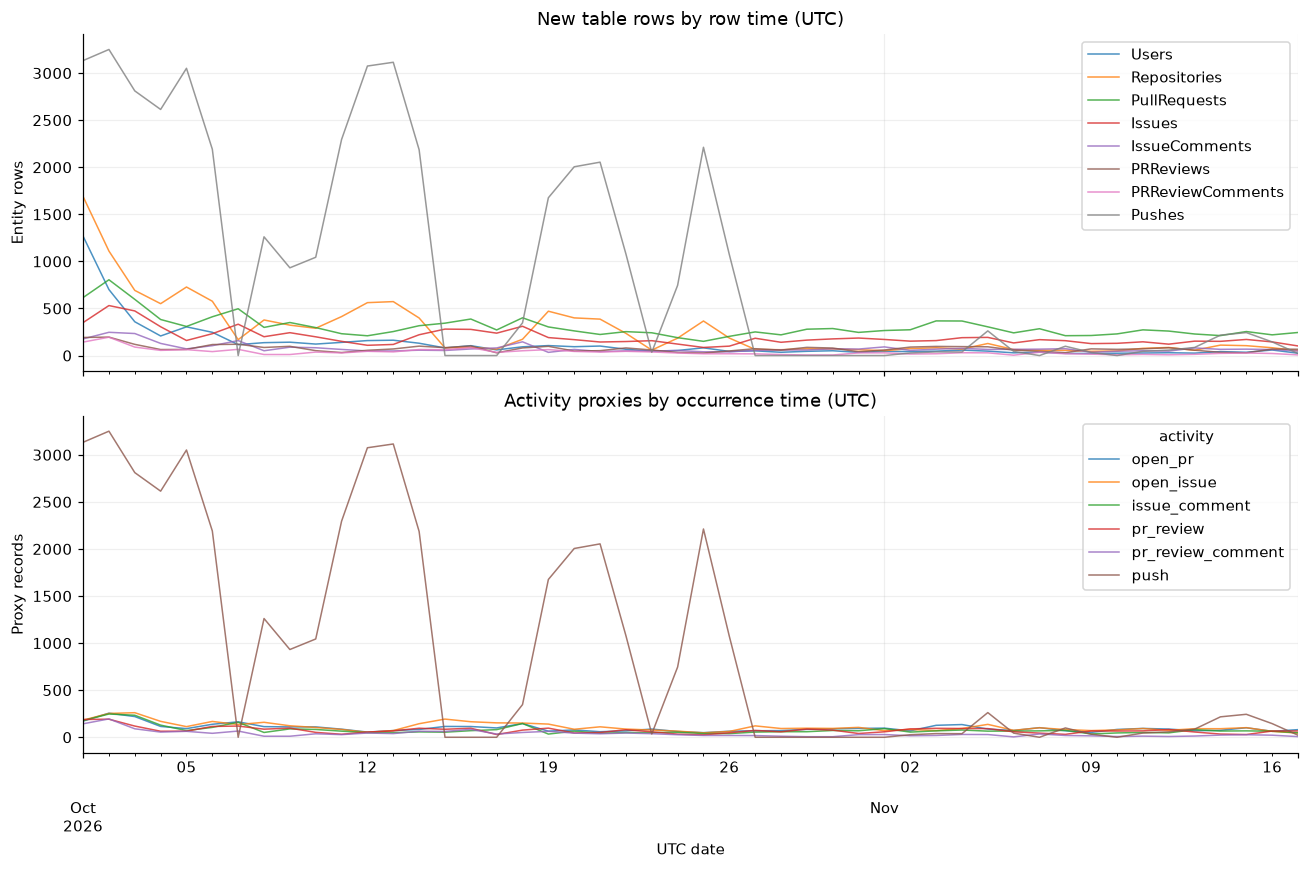

activity,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
week_start_utc (rates %),,,,,,
2026-10-03 16:00:00,5.26,2.77,3.54,3.48,1.71,24.27
2026-10-10 16:00:00,4.37,2.62,2.59,3.11,2.08,23.67
2026-10-17 16:00:00,3.87,2.50,2.36,2.50,1.90,20.53
2026-10-24 16:00:00,3.70,1.97,2.49,2.66,0.83,11.21
2026-10-31 16:00:00,4.26,2.18,2.84,3.06,1.17,3.14
2026-11-07 16:00:00,3.76,2.02,2.28,2.59,0.77,3.08


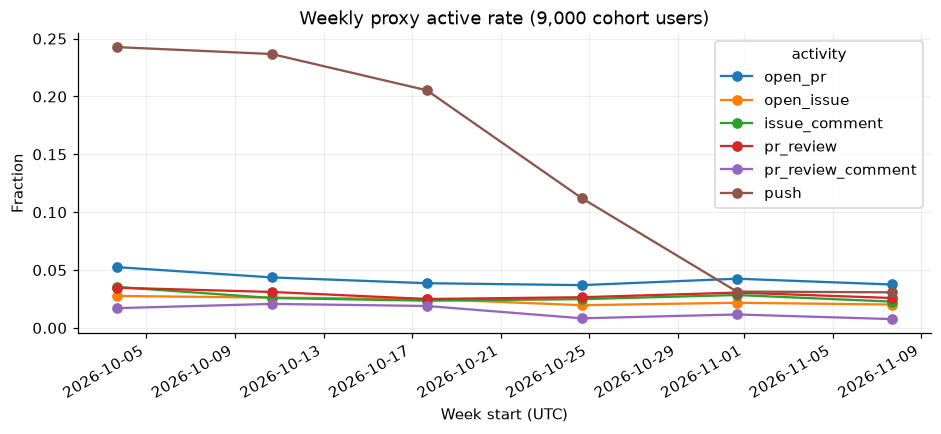

In [9]:
days = pd.date_range(DATA_START, DATA_END, freq='D', inclusive='left')
daily_arrivals = pd.DataFrame({
    name: df.groupby(df[TABLES[name]['time']].dt.floor('D')).size().reindex(days, fill_value=0)
    for name, df in tables.items()
})
daily_proxy = (activity_records.groupby(['day_utc', 'activity']).size().unstack(fill_value=0)
               .reindex(index=days, columns=EVENTS, fill_value=0))
daily_arrivals.index.name = daily_proxy.index.name = 'day_utc'
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
daily_arrivals.plot(ax=axes[0], linewidth=1, alpha=.8)
axes[0].set(title='New table rows by row time (UTC)', ylabel='Entity rows')
daily_proxy.plot(ax=axes[1], linewidth=1, alpha=.8)
axes[1].set(title='Activity proxies by occurrence time (UTC)', ylabel='Proxy records', xlabel='UTC date')
fig.tight_layout()
save_figure(fig, 'daily_trends.png')

weeks = []
start = TEST_START
while start >= DATA_START:
    if start + pd.Timedelta(days=7) <= DATA_END:
        weeks.append(start)
    start -= pd.Timedelta(days=7)
weekly_rows = []
for start in sorted(weeks):
    end = start + pd.Timedelta(days=7)
    available = activity_records.loc[
        activity_records['event_time'].ge(start) & activity_records['event_time'].lt(end)
        & activity_records['available_at'].lt(end)]
    counts = available.groupby('activity')['github_user_id'].nunique().reindex(EVENTS, fill_value=0)
    for activity in EVENTS:
        weekly_rows.append({'week_start_utc': start, 'week_end_utc_exclusive': end,
                             'activity': activity, 'active_cohort_users': int(counts[activity]),
                             'cohort_denominator': len(cohort_ids),
                             'proxy_active_rate': counts[activity] / len(cohort_ids)})
weekly_proxy = pd.DataFrame(weekly_rows)
if len(weekly_proxy):
    week_rates = weekly_proxy.pivot(index='week_start_utc', columns='activity', values='proxy_active_rate').reindex(columns=EVENTS)
    display((100 * week_rates).round(2).rename_axis('week_start_utc (rates %)'))
    fig, ax = plt.subplots(figsize=(10, 4))
    week_rates.plot(ax=ax, marker='o')
    ax.set(title='Weekly proxy active rate (9,000 cohort users)', ylabel='Fraction', xlabel='Week start (UTC)')
    save_figure(fig, 'weekly_proxy_rates.png')

### 每日低量／零量診斷

各活動分開畫圖，避免 push 的量級蓋過其他類別。紅點表示該日這個 proxy 計數為零。
下方一起顯示原始檔案數和大小，以便先區分缺少檔案與來源／cohort 觀測量變化。
即使一天有 24 個完整檔案，也無法只憑這裡判定某類活動為零的原因。
這些日期應列入後續資料品質檢查，不能直接當成使用者沒有活動的證據。

,zero_proxy_days
activity,
open_pr,0
open_issue,0
issue_comment,0
pr_review,0
pr_review_comment,0
push,12


,day_utc,activity,zero_proxy_count,available_hours,raw_bytes
0,2026-10-07,push,True,24,196956323
1,2026-10-15,push,True,24,130385477
2,2026-10-16,push,True,24,152777946
3,2026-10-17,push,True,24,147077838
4,2026-10-27,push,True,24,93648281
5,2026-10-28,push,True,24,90991635
6,2026-10-29,push,True,24,98787569
7,2026-10-30,push,True,24,106986563
8,2026-10-31,push,True,24,129844083
9,2026-11-01,push,True,24,141445612


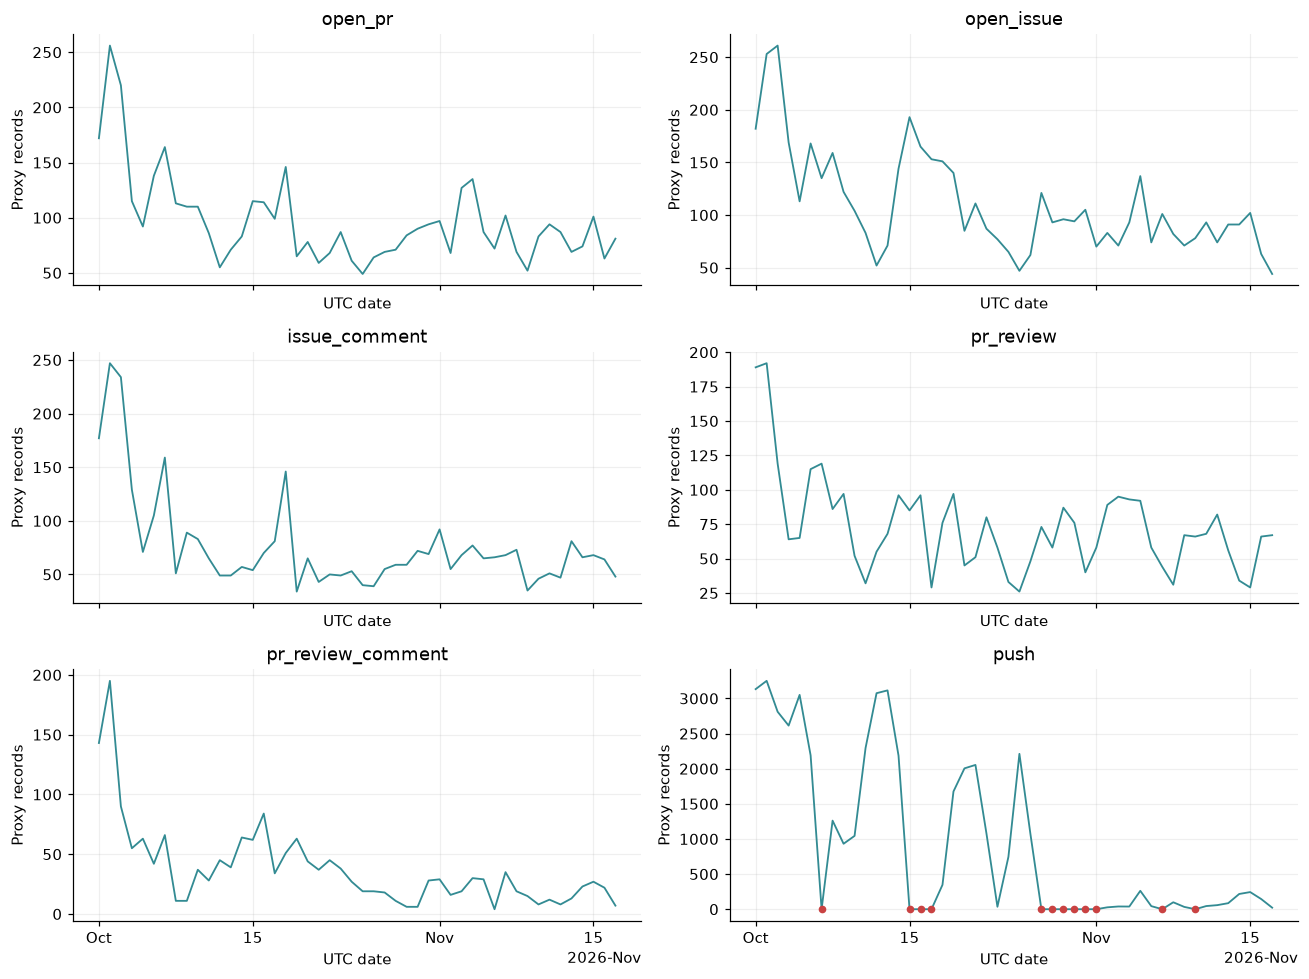

In [10]:
daily_quality = daily_files.join(daily_proxy.add_suffix('_proxy'))
zero_proxy_days = (daily_proxy.eq(0).rename_axis(columns='activity').stack()
                   .loc[lambda s: s].reset_index(name='zero_proxy_count'))
zero_proxy_days = zero_proxy_days.merge(
    daily_files, left_on='day_utc', right_index=True, how='left', validate='many_to_one')
display(daily_proxy.eq(0).sum().rename('zero_proxy_days').to_frame())
display(zero_proxy_days.sort_values('day_utc').tail(15))
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, activity in zip(axes.flat, EVENTS):
    ax.plot(daily_proxy.index.to_pydatetime(), daily_proxy[activity].to_numpy(),
            linewidth=1.2, color='#338b93')
    zeros = daily_proxy.index[daily_proxy[activity].eq(0)]
    if len(zeros):
        ax.plot(zeros.to_pydatetime(), np.zeros(len(zeros)), linestyle='none',
                marker='o', color='#c94242', markersize=4, zorder=3)
    ax.set(title=activity, ylabel='Proxy records', xlabel='UTC date')
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.tight_layout()
save_figure(fig, 'activity_proxy_panels.png')

## 8. 使用者活躍度、近期性與冷啟動

以下統計仍是上述 proxy 的觀察結果。用完整測試清單做 left join，沒有觀察的記錄數補 0，
但最近活動日期保留缺值，另加指示欄位。區分「無 Users 列」與「有列但沒有這裡定義的 proxy」。
不要把 user_id 當作數值特徵，也不要因為沒有歷史而漏掉提交列。

,proxy_records,active_days,distinct_repositories,days_since_last_proxy
count,9000.00,9000.00,9000.00,4205.00
mean,6.94,2.61,1.37,22.10
std,31.27,5.10,3.55,14.42
min,0.00,0.00,0.00,0.01
50%,0.00,0.00,0.00,23.43
90%,14.00,8.00,3.00,42.54
95%,28.00,13.00,5.00,44.84
99%,105.01,25.00,13.00,47.44
max,1111.00,46.00,151.00,47.98


,test_users,without_user_row,without_activity_proxy,present_but_no_proxy,last_proxy_more_than_7d_ago
0,4465,733,775,42,2739


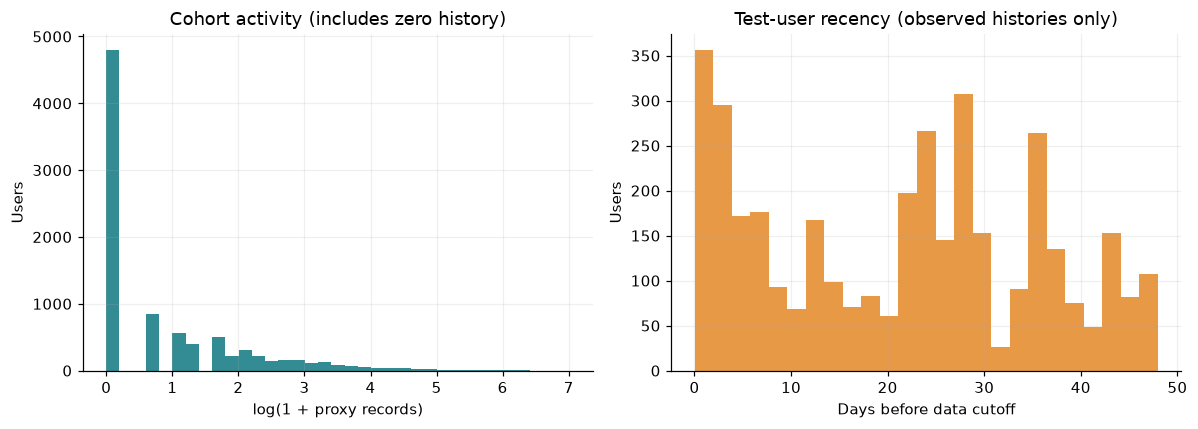

In [11]:
user_stats = activity_records.groupby('github_user_id').agg(
    proxy_records=('activity', 'size'), active_days=('day_utc', 'nunique'),
    distinct_repositories=('repo_id', 'nunique'), last_proxy_time=('event_time', 'max'))
all_cohort_stats = pd.DataFrame({'github_user_id': sorted(cohort_ids)}).merge(
    user_stats, on='github_user_id', how='left', validate='one_to_one')
count_columns = ['proxy_records', 'active_days', 'distinct_repositories']
all_cohort_stats[count_columns] = all_cohort_stats[count_columns].fillna(0).astype('int64')
all_cohort_stats['days_since_last_proxy'] = (
    DATA_END - all_cohort_stats['last_proxy_time']).dt.total_seconds() / 86400
test_history = test_history.merge(
    all_cohort_stats, left_on='UserID', right_on='github_user_id', how='left',
    suffixes=('', '_stats'), validate='one_to_one')
test_history['no_observed_proxy'] = test_history['proxy_records'].eq(0)
display(all_cohort_stats[count_columns + ['days_since_last_proxy']]
        .describe(percentiles=[.5, .9, .95, .99]).round(2))
display(pd.DataFrame([{
    'test_users': len(test_history),
    'without_user_row': int((~test_history['has_user_row']).sum()),
    'without_activity_proxy': int(test_history['no_observed_proxy'].sum()),
    'present_but_no_proxy': int((test_history['has_user_row'] & test_history['no_observed_proxy']).sum()),
    'last_proxy_more_than_7d_ago': int(test_history['days_since_last_proxy'].gt(7).sum()),
}]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log1p(all_cohort_stats['proxy_records']), bins=35, color='#338b93')
axes[0].set(title='Cohort activity (includes zero history)', xlabel='log(1 + proxy records)', ylabel='Users')
axes[1].hist(test_history['days_since_last_proxy'].dropna(), bins=25, color='#e79945')
axes[1].set(title='Test-user recency (observed histories only)', xlabel='Days before data cutoff', ylabel='Users')
fig.tight_layout()
save_figure(fig, 'user_activity_and_recency.png')

## 9. 關聯表如何查詢：Push → User → Repository

以外鍵 join，不是拿匿名化 code 互接。`many_to_one` 能抓到意外的鍵重複。
下方範例刻意只查閱，沒有把最終快照中的使用者或 repo 屬性當作歷史特徵。

In [12]:
push_view = (tables['Pushes'].sort_values('created_at').tail(10)
    .merge(users[['user_id', 'github_user_id', 'is_cohort']],
           on='user_id', how='left', validate='many_to_one')
    .merge(tables['Repositories'][['repo_id', 'name', 'owner_login']],
           on='repo_id', how='left', validate='many_to_one'))
display(push_view[['created_at', 'github_user_id', 'is_cohort', 'repo_id', 'name', 'ref_type', 'branch']])
repo_activity = activity_records.groupby('repo_id').agg(
    proxy_records=('activity', 'size'), cohort_users=('github_user_id', 'nunique'))
display(repo_activity.nlargest(10, 'proxy_records'))

,created_at,github_user_id,is_cohort,repo_id,name,ref_type,branch
0,2026-11-17 14:33:17,292011191146237,True,132,dfd91dce3c8b82a1/aaaa,branch,aaa/aaaaaa-aaaaaaaaaa
1,2026-11-17 14:33:19,593942352729887,True,704,123c9d153db2fff3/aaaaaaa,branch,aaaa-aaa
2,2026-11-17 14:37:00,196591250987766,True,1597,c07ba11932ce18b0/aaaaaaa,branch,aaaaa/aaaaaaa-aaaaaa-aaa-aaaaaaaaaa
3,2026-11-17 15:01:13,980761147672700,True,12712,e0c0b705ee4f54f4/aaaaa-aaa,branch,aaaaaaaaaaa-aaaaaa-aaaaa-aaaaaaaaaa
4,2026-11-17 15:01:23,688866239453790,True,11651,612c572ac979913e/aaaaaa-aaaaaaa,branch,aaaaaa/aaaaaaa-aaaaaa-aaa0aa-a000-aaaaaaa
5,2026-11-17 15:01:51,991564005246869,True,12713,f80e52977f1dbba9/aaaaaa,branch,aaaa-aaaaaaa-aaaa
6,2026-11-17 15:02:56,688866239453790,True,11651,612c572ac979913e/aaaaaa-aaaaaaa,branch,aaaaaa/aaaaaaa-aaaaaa-aaa0aa-a000
7,2026-11-17 15:06:07,838534852014232,True,12329,8e470a7d4bb5ddbf/aaa,branch,aaaaaa/aaaa-a0-aaaaaa-aaaaaa
8,2026-11-17 15:06:55,817457692133452,True,12396,c1e3adcbd930a9cc/aa-aaaa-aaaa,branch,aaaa
9,2026-11-17 15:08:11,435600524664468,True,12715,dee1b68dfbe4e759/aaaa-aaaa-aaa,branch,aaaa


,proxy_records,cohort_users
repo_id,,
17,584,1
210,516,1
106,505,1
56,428,1
3,390,1
109,356,1
73,337,1
1,305,1
8805,293,1


## 10. 後續時間切分與特徵入口

先用下面的函式取得預測時間 t 前已可見的 **proxy 歷史窗口**。同時限制活動時間與可見時間，
不使用 merged／closed 等最終狀態欄位。這只是初步的歷史計數入口，還不是正式標籤建置流程。
驗證週可選上方列出的完整週；特徵在週起點截斷，答案週另外建置。
超參數、閾值和缺歷史策略應只用歷史驗證週決定。

最終預測需要在測試起點前再補資料；目前截止時間仍早於測試週起點。

In [13]:
def observed_proxy_window(cutoff_utc, lookback_days=7):
    cutoff = pd.Timestamp(cutoff_utc)
    if cutoff.tzinfo is not None:
        cutoff = cutoff.tz_convert('UTC').tz_localize(None)
    if not DATA_START < cutoff <= DATA_END:
        raise ValueError('cutoff 必須在已建置資料範圍內。')
    if lookback_days <= 0:
        raise ValueError('lookback_days 必須為正。')
    begin = cutoff - pd.Timedelta(days=lookback_days)
    if begin < DATA_START:
        raise ValueError('歷史窗口超出資料起點。')
    return activity_records.loc[
        activity_records['available_at'].lt(cutoff)
        & activity_records['event_time'].ge(begin)
        & activity_records['event_time'].lt(cutoff)].copy()

recent = observed_proxy_window(DATA_END, 7)
recent_counts = recent.groupby(['github_user_id', 'activity']).size().unstack(fill_value=0)
recent_counts = recent_counts.reindex(columns=EVENTS, fill_value=0)
recent_test = test_input.merge(recent_counts, left_on='UserID', right_index=True,
                               how='left', validate='one_to_one')
recent_test[EVENTS] = recent_test[EVENTS].fillna(0).astype('int64')
assert len(recent_test) == len(test_input)
assert recent['available_at'].lt(DATA_END).all() and recent['event_time'].lt(DATA_END).all()
display(recent_test.head(10))
print('這是最近七天的歷史 proxy 計數，不是測試週的預測或標籤。')

,UserID,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,100431196554039,0,5,3,0,0,1
1,100457905686263,0,0,0,0,0,0
2,101051236896852,0,0,0,0,0,0
3,101306412508088,0,0,0,0,0,0
4,101380187937965,2,0,2,0,0,0
5,101397660206993,0,0,0,0,1,0
6,101504824442042,0,0,0,0,0,0
7,101676995697352,0,0,0,0,0,0
8,101869085002773,0,0,0,0,0,0
9,102136149571463,0,0,0,0,0,0


這是最近七天的歷史 proxy 計數，不是測試週的預測或標籤。


## 11. 保存分析結果與本次發現

下面的文字由本次資料動態生成。更新資料後重新 Run All，即可重新產生圖表、CSV 與摘要。
`no_observed_proxy` 不等於未來的負標籤；初探得到的比例也不是正式測試週的真實活動率。

In [14]:
exports = {
    'table_overview': overview, 'column_profile': column_profile,
    'foreign_key_profile': fk_profile, 'daily_file_coverage': daily_files,
    'user_coverage': coverage, 'availability_lags': lag_summary,
    'activity_proxy_audit': proxy_audit, 'activity_proxy_summary': activity_summary,
    'daily_table_arrivals': daily_arrivals, 'daily_activity_proxies': daily_proxy,
    'weekly_activity_proxy_rates': weekly_proxy, 'cohort_user_activity': all_cohort_stats,
    'test_user_history': test_history, 'test_user_recent_7d_proxy_counts': recent_test,
    'daily_activity_quality': daily_quality, 'zero_proxy_days': zero_proxy_days,
}
indexed = {'table_overview', 'daily_file_coverage', 'availability_lags', 'activity_proxy_audit',
           'activity_proxy_summary', 'daily_table_arrivals', 'daily_activity_proxies', 'daily_activity_quality'}
for name, frame in exports.items():
    frame.to_csv(OUT / f'{name}.csv', index=name in indexed)
missing_users = test_history.loc[~test_history['has_user_row'], ['UserID']]
missing_users.to_csv(OUT / 'test_users_without_observed_history.csv', index=False)
largest = activity_summary['proxy_records'].idxmax()
push_zero_day_count = int(daily_proxy['push'].eq(0).sum())
push_week_rates = weekly_proxy.loc[weekly_proxy['activity'].eq('push')].sort_values('week_start_utc')
push_change_text = ''
if len(push_week_rates) >= 2:
    push_change_text = (f"- 完整歷史週的 push proxy 活躍率由首週 "
                        f"**{100 * push_week_rates.iloc[0]['proxy_active_rate']:.2f}%** "
                        f"變成末週 **{100 * push_week_rates.iloc[-1]['proxy_active_rate']:.2f}%**。"
                        '此為觀測變化，不能直接歸因於真實行為或來源缺漏；應在建模前確認穩定性。')
summary = {
    'data_start_utc_inclusive': DATA_START.isoformat(),
    'data_end_utc_exclusive': DATA_END.isoformat(),
    'downloaded_hours': len(files), 'table_rows': {name: len(df) for name, df in tables.items()},
    'test_users': len(test_history), 'test_users_without_user_row': len(missing_users),
    'test_users_without_activity_proxy': int(test_history['no_observed_proxy'].sum()),
    'activity_proxy_records': {e: int(activity_summary.loc[e, 'proxy_records']) for e in EVENTS},
    'complete_test_aligned_weeks': len(weeks),
    'zero_push_proxy_days': push_zero_day_count,
    'interpretation': 'Descriptive table-derived proxies; not official truth or complete raw events.',
}
(OUT / 'eda_summary.json').write_text(json.dumps(summary, indent=2) + '\n')
display(Markdown(f"""
### 本次資料觀察

- 範圍：UTC **{DATA_START} 至 {DATA_END}（不含）**，共 **{len(files):,}** 個小時檔。
- 正式測試使用者 **{len(test_history):,}** 位，其中 **{len(missing_users):,}** 位沒有 Users 列；
  **{int(test_history['no_observed_proxy'].sum()):,}** 位沒有本 Notebook 定義的活動 proxy。
- 計數最多的 proxy 是 **{largest}**，有 **{int(activity_summary.loc[largest, 'proxy_records']):,}** 筆；
  建模時需留意活動類別與使用者之間的不均衡。
- 本段資料涵蓋 **{len(weeks)}** 個完整、與測試週邊界對齊的歷史週。
- 全期間有 **{push_zero_day_count}** 天的 push proxy 計數為零；詳見每日診斷與來源檔案覆蓋率。
{push_change_text}
- 接下來先確認標籤政策，建立歷史週驗證與 Copy-last-week 參考，再比較使用近 7／14／28 天的計數、
  活躍天數、近期性與 repo 多樣性的特徵。

輸出目錄：`{OUT.relative_to(ROOT)}/`。
"""))


### 本次資料觀察

- 範圍：UTC **2026-10-01 00:00:00 至 2026-11-18 00:00:00（不含）**，共 **1,152** 個小時檔。
- 正式測試使用者 **4,465** 位，其中 **733** 位沒有 Users 列；
  **775** 位沒有本 Notebook 定義的活動 proxy。
- 計數最多的 proxy 是 **push**，有 **43,545** 筆；
  建模時需留意活動類別與使用者之間的不均衡。
- 本段資料涵蓋 **6** 個完整、與測試週邊界對齊的歷史週。
- 全期間有 **12** 天的 push proxy 計數為零；詳見每日診斷與來源檔案覆蓋率。
- 完整歷史週的 push proxy 活躍率由首週 **24.27%** 變成末週 **3.08%**。此為觀測變化，不能直接歸因於真實行為或來源缺漏；應在建模前確認穩定性。
- 接下來先確認標籤政策，建立歷史週驗證與 Copy-last-week 參考，再比較使用近 7／14／28 天的計數、
  活躍天數、近期性與 repo 多樣性的特徵。

輸出目錄：`data/analysis/`。
